<table width="100%">
<tr>
<td width="16%" align="left"><img src="reporte/logo_uach.png" width="110"></td>
<td align="center"><h2>Universidad Autónoma de Chihuahua</h2><h3>Facultad de Ingeniería</h3><b>Maestría en Ingeniería en Computación</b></td>
<td width="16%" align="right"><img src="reporte/logo_fing.png" width="110"></td>
</tr>
</table>

<p align="center"><b><font size="6">Proyecto Final 1:<br>Optimización de Rutas y Eficiencia de Combustible</font></b></p>

<p align="center"><i>Estadística Aplicada a la Investigación</i><br><b><i>Catedrático:</i></b> <i>Dr. José Saul De Lira Miramontes</i></p>

<p align="right"><b><i>Alumno:</i></b><br><b>345491</b> González Cardoza Jonahtan</p>

<p align="center">25 de noviembre de 2026</p>

## Introducción

| Dato | Detalle |
|---|---|
| **Alumno** | González Cardoza Jonahtan (matrícula 345491) |
| **Programa** | Maestría en Ingeniería en Computación, Facultad de Ingeniería, Universidad Autónoma de Chihuahua |
| **Materia** | Estadística Aplicada a la Investigación |
| **Catedrático** | Dr. José Saul De Lira Miramontes |
| **Entrega** | 25 de noviembre de 2026 |

**El caso.** FastTrack Logistics es una empresa mediana de transporte de carga terrestre que opera en el centro del país y se especializa en entregas *Just-in-Time* para el sector industrial. En el último trimestre fiscal sus costos operativos subieron 18 %, impulsados casi por completo por el gasto en diésel. La empresa quiere saber qué factores explican el consumo de combustible de su flota.

**Objetivos.**
- Determinar si hay diferencias significativas en el consumo según el tipo de ruta (Urbana, Autopista, Montaña).
- Identificar la relación entre velocidad, peso de la carga y consumo.
- Construir un modelo predictivo del consumo y responder las preguntas de negocio de la dirección.

**Datos.** `dataset/datos_logistica_transporte1.csv`: 50 viajes con `Tipo_Ruta`, `Peso_Carga_Ton`, `Velocidad_Promedio_kmh` y `Consumo_Litros`.

**Fases de este cuaderno:** (0) carga de datos, (1) estadística descriptiva y ANOVA, (2) correlación de Pearson, (3) regresión lineal múltiple, (4) pronóstico y (5) toma de decisiones. Nivel de significancia: α = 0.05.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

alpha = 0.05
routes = ["Urbana", "Autopista", "Montaña"]
markers = {"Urbana": "o", "Autopista": "s", "Montaña": "^"}
grays = {"Urbana": "0.75", "Autopista": "0.45", "Montaña": "0.05"}
os.makedirs("reporte/figuras", exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=1.05)
pd.set_option("display.precision", 4)

## 0. Carga y revisión de los datos
El CSV viene con codificación de Windows antigua (cp850); si se lee como UTF-8, "Montaña" sale mal escrita.

In [2]:
data = pd.read_csv("dataset/datos_logistica_transporte1.csv", encoding="cp850")
data["Tipo_Ruta"] = pd.Categorical(data["Tipo_Ruta"], categories=routes)

print("Filas y columnas:", data.shape)
print("Datos faltantes:", data.isna().sum().sum())
print("Filas duplicadas:", data.duplicated().sum())
print("\nViajes por tipo de ruta:")
print(data["Tipo_Ruta"].value_counts().reindex(routes))

data.to_csv("dataset/datos_logistica_transporte.csv", index=False, encoding="utf-8")
print("\nDataset limpio guardado en UTF-8: dataset/datos_logistica_transporte.csv")
data.head()

Filas y columnas: (50, 5)
Datos faltantes: 0
Filas duplicadas: 0

Viajes por tipo de ruta:
Tipo_Ruta
Urbana       21
Autopista    15
Montaña      14
Name: count, dtype: int64

Dataset limpio guardado en UTF-8: dataset/datos_logistica_transporte.csv


,ID_Viaje,Tipo_Ruta,Peso_Carga_Ton,Velocidad_Promedio_kmh,Consumo_Litros
0,1,Autopista,27.27,89.4,54.0
1,2,Montaña,22.60,52.7,79.2
2,3,Montaña,26.55,50.3,87.9
3,4,Autopista,25.48,102.7,54.9
4,5,Urbana,18.35,43.2,52.6


## 1. Análisis exploratorio y ANOVA
### 1.1 Estadística descriptiva

In [3]:
numeric_cols = ["Peso_Carga_Ton", "Velocidad_Promedio_kmh", "Consumo_Litros"]
print("Estadística descriptiva general:")
print(data[numeric_cols].describe().round(2))

desc_route = data.groupby("Tipo_Ruta", observed=True)["Consumo_Litros"].agg(["count", "mean", "std", "min", "max"])
desc_route["cv_%"] = 100 * desc_route["std"] / desc_route["mean"]
print("\nConsumo (L) por tipo de ruta:")
print(desc_route.round(2))

means_route = data.groupby("Tipo_Ruta", observed=True)[numeric_cols].mean()
print("\nPromedio de cada variable por ruta:")
print(means_route.round(2))

Estadística descriptiva general:
       Peso_Carga_Ton  Velocidad_Promedio_kmh  Consumo_Litros
count           50.00                   50.00           50.00
mean            15.41                   56.56           51.13
std              7.15                   27.05           19.01
min              4.11                   20.40           27.20
25%              8.86                   38.72           38.30
50%             15.60                   45.45           42.55
75%             20.65                   85.20           56.02
max             27.28                  104.50           90.40

Consumo (L) por tipo de ruta:
           count   mean    std   min   max   cv_%
Tipo_Ruta                                        
Urbana        21  42.27   9.71  27.2  63.3  22.97
Autopista     15  41.25   7.21  27.3  54.9  17.48
Montaña       14  75.01  17.53  40.3  90.4  23.37

Promedio de cada variable por ruta:
           Peso_Carga_Ton  Velocidad_Promedio_kmh  Consumo_Litros
Tipo_Ruta                

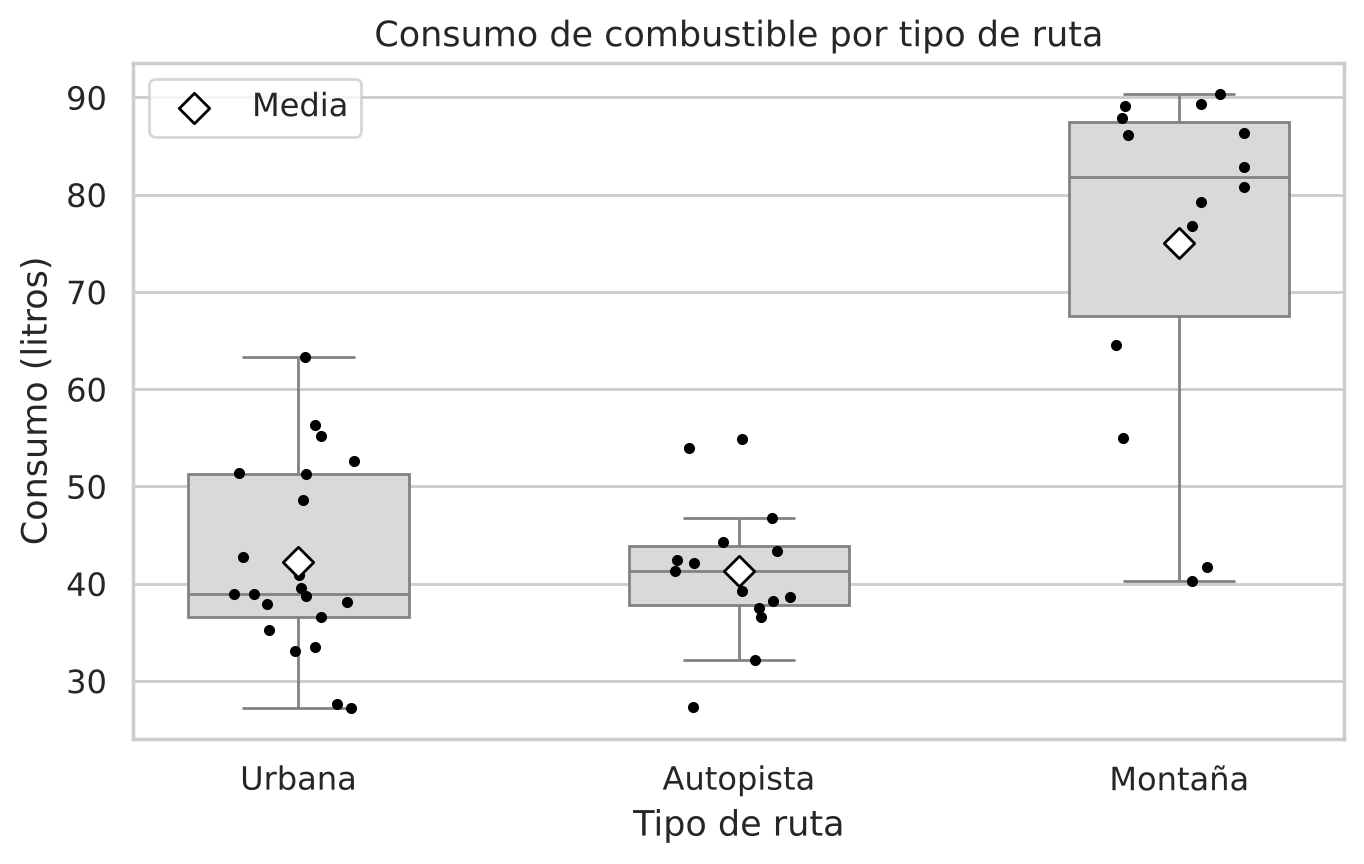

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=data, x="Tipo_Ruta", y="Consumo_Litros", order=routes, color="0.85", width=0.5, showfliers=False, ax=ax)
sns.stripplot(data=data, x="Tipo_Ruta", y="Consumo_Litros", order=routes, color="black", size=4, jitter=0.15, ax=ax)
ax.scatter(range(3), desc_route.loc[routes, "mean"], marker="D", s=60, color="white", edgecolor="black", zorder=5, label="Media")
ax.set_xlabel("Tipo de ruta")
ax.set_ylabel("Consumo (litros)")
ax.set_title("Consumo de combustible por tipo de ruta")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("reporte/figuras/fig1_boxplot_ruta.pdf")
fig.savefig("reporte/figuras/fig1_boxplot_ruta.png", dpi=150)
plt.show()

### 1.2 ANOVA de un factor
$H_0: \mu_{Urbana} = \mu_{Autopista} = \mu_{Montaña}$ (el consumo medio es igual en las tres rutas)

$H_1$: al menos una media es diferente.

In [5]:
groups = [data.loc[data["Tipo_Ruta"] == r, "Consumo_Litros"] for r in routes]
f_stat, p_value = stats.f_oneway(*groups)
k = len(routes)
n_total = len(data)
f_crit = stats.f.ppf(1 - alpha, k - 1, n_total - k)

anova_model = smf.ols("Consumo_Litros ~ C(Tipo_Ruta)", data=data).fit()
anova_table = anova_lm(anova_model)
anova_table.index = ["Entre rutas", "Dentro (error)"]
anova_table.columns = ["gl", "SC", "CM", "F", "valor p"]
ss_between = anova_table.loc["Entre rutas", "SC"]
ss_total = anova_table["SC"].sum()
eta2 = ss_between / ss_total

print("Tabla ANOVA:")
print(anova_table.to_string(float_format=lambda v: f"{v:.4f}", formatters={"valor p": lambda v: "" if pd.isna(v) else f"{v:.3e}"}, na_rep=""))
print(f"\nF = {f_stat:.4f}   F crítico (0.05; {k-1}; {n_total-k}) = {f_crit:.4f}")
print(f"Valor p = {p_value:.3e}")
print(f"Eta cuadrada = {eta2:.4f}  ({eta2*100:.1f} % de la variación del consumo se explica por la ruta)")
if p_value < alpha:
    print("\nDecisión: se rechaza H0. El consumo medio NO es igual en las tres rutas.")
else:
    print("\nDecisión: no se rechaza H0.")

Tabla ANOVA:
                    gl         SC        CM       F   valor p
Entre rutas     2.0000 11099.3877 5549.6938 39.4650 8.735e-11
Dentro (error) 47.0000  6609.2811  140.6230                  

F = 39.4650   F crítico (0.05; 2; 47) = 3.1951
Valor p = 8.735e-11
Eta cuadrada = 0.6268  (62.7 % de la variación del consumo se explica por la ruta)

Decisión: se rechaza H0. El consumo medio NO es igual en las tres rutas.


**Interpretación del valor p:** si las tres rutas consumieran lo mismo en promedio, la probabilidad de ver diferencias tan grandes como estas sería prácticamente cero (p ≈ 9 × 10⁻¹¹). Por eso se concluye que la ruta sí influye en el consumo.

### 1.3 Supuestos y prueba post hoc (Tukey)

In [6]:
print("Normalidad de los residuos (Shapiro-Wilk):")
sw_stat, sw_p = stats.shapiro(anova_model.resid)
print(f"  W = {sw_stat:.4f}, p = {sw_p:.4f}")
print("Normalidad por grupo (Shapiro-Wilk):")
for r, g in zip(routes, groups):
    w, p = stats.shapiro(g)
    print(f"  {r:10s} W = {w:.4f}, p = {p:.4f}")
lev_stat, lev_p = stats.levene(*groups)
print(f"Igualdad de varianzas (Levene): W = {lev_stat:.4f}, p = {lev_p:.4f}")
kw_stat, kw_p = stats.kruskal(*groups)
print(f"Kruskal-Wallis (confirmación no paramétrica): H = {kw_stat:.4f}, p = {kw_p:.3e}")
print("\nPrueba de Tukey HSD (comparaciones por pares):")
tukey = pairwise_tukeyhsd(data["Consumo_Litros"], data["Tipo_Ruta"].astype(str), alpha=alpha)
print(tukey.summary())

Normalidad de los residuos (Shapiro-Wilk):
  W = 0.9420, p = 0.0162
Normalidad por grupo (Shapiro-Wilk):
  Urbana     W = 0.9440, p = 0.2614
  Autopista  W = 0.9576, p = 0.6504
  Montaña    W = 0.7968, p = 0.0046
Igualdad de varianzas (Levene): W = 2.4456, p = 0.0976
Kruskal-Wallis (confirmación no paramétrica): H = 21.9869, p = 1.681e-05

Prueba de Tukey HSD (comparaciones por pares):


   Multiple Comparison of Means - Tukey HSD, FWER=0.05    
  group1   group2 meandiff p-adj   lower    upper   reject
----------------------------------------------------------
Autopista Montaña   33.761    0.0  23.0961  44.4258   True
Autopista  Urbana   1.0133 0.9654  -8.6887  10.7153  False
  Montaña  Urbana -32.7476    0.0 -42.6497 -22.8456   True
----------------------------------------------------------


**Lectura:** Montaña consume en promedio unos 33–34 L más que Urbana y Autopista, y esas dos diferencias son significativas. Urbana y Autopista **no** difieren entre sí (p ≈ 0.97).

Supuestos: las varianzas pueden considerarse iguales (Levene p = 0.098 > 0.05). La normalidad se cumple en Urbana y Autopista pero no en Montaña (p = 0.005), porque ahí hay unos pocos viajes con carga ligera que consumen mucho menos que el resto. El ANOVA aguanta bien desviaciones moderadas de normalidad y, además, la prueba no paramétrica de Kruskal-Wallis (que no supone normalidad) da la misma conclusión (p ≈ 2 × 10⁻⁵), así que el resultado es confiable.

## 2. Análisis de correlación (Pearson)

In [7]:
corr_matrix = data[numeric_cols].corr(method="pearson")
print("Matriz de correlación de Pearson:")
print(corr_matrix.round(4))

print("\nPruebas de significancia (H0: rho = 0):")
pairs = [("Peso_Carga_Ton", "Consumo_Litros"), ("Velocidad_Promedio_kmh", "Consumo_Litros"), ("Peso_Carga_Ton", "Velocidad_Promedio_kmh")]
for a, b in pairs:
    r, p = stats.pearsonr(data[a], data[b])
    print(f"  r({a}, {b}) = {r:.4f}, p = {p:.3e}")

strongest = corr_matrix["Consumo_Litros"].drop("Consumo_Litros").abs().idxmax()
print(f"\nVariable con la relación más fuerte con el consumo: {strongest} (r = {corr_matrix.loc[strongest, 'Consumo_Litros']:.4f})")

print("\nCorrelación con el consumo dentro de cada ruta:")
for r in routes:
    sub = data[data["Tipo_Ruta"] == r]
    r_w = stats.pearsonr(sub["Peso_Carga_Ton"], sub["Consumo_Litros"])[0]
    r_v = stats.pearsonr(sub["Velocidad_Promedio_kmh"], sub["Consumo_Litros"])[0]
    print(f"  {r:10s} r(peso) = {r_w:.3f}   r(velocidad) = {r_v:.3f}")

Matriz de correlación de Pearson:
                        Peso_Carga_Ton  Velocidad_Promedio_kmh  Consumo_Litros
Peso_Carga_Ton                  1.0000                  0.2509          0.8428
Velocidad_Promedio_kmh          0.2509                  1.0000         -0.0939
Consumo_Litros                  0.8428                 -0.0939          1.0000

Pruebas de significancia (H0: rho = 0):
  r(Peso_Carga_Ton, Consumo_Litros) = 0.8428, p = 1.640e-14
  r(Velocidad_Promedio_kmh, Consumo_Litros) = -0.0939, p = 5.167e-01
  r(Peso_Carga_Ton, Velocidad_Promedio_kmh) = 0.2509, p = 7.884e-02

Variable con la relación más fuerte con el consumo: Peso_Carga_Ton (r = 0.8428)

Correlación con el consumo dentro de cada ruta:
  Urbana     r(peso) = 0.969   r(velocidad) = 0.598
  Autopista  r(peso) = 0.972   r(velocidad) = 0.023
  Montaña    r(peso) = 0.996   r(velocidad) = 0.384


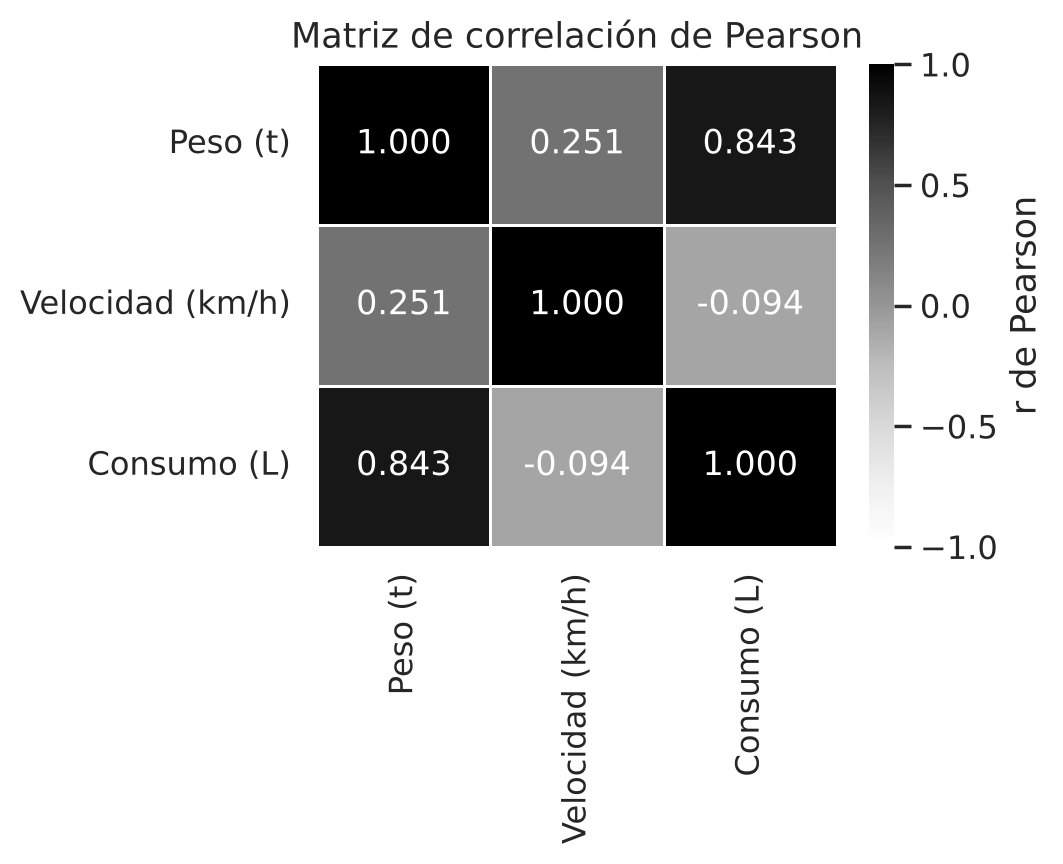

In [8]:
labels = {"Peso_Carga_Ton": "Peso (t)", "Velocidad_Promedio_kmh": "Velocidad (km/h)", "Consumo_Litros": "Consumo (L)"}
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr_matrix.rename(index=labels, columns=labels), annot=True, fmt=".3f", cmap="Greys", vmin=-1, vmax=1,
            linewidths=1, linecolor="white", cbar_kws={"label": "r de Pearson"}, ax=ax, annot_kws={"size": 12})
ax.set_title("Matriz de correlación de Pearson")
fig.tight_layout()
fig.savefig("reporte/figuras/fig2_correlacion.pdf")
fig.savefig("reporte/figuras/fig2_correlacion.png", dpi=150)
plt.show()

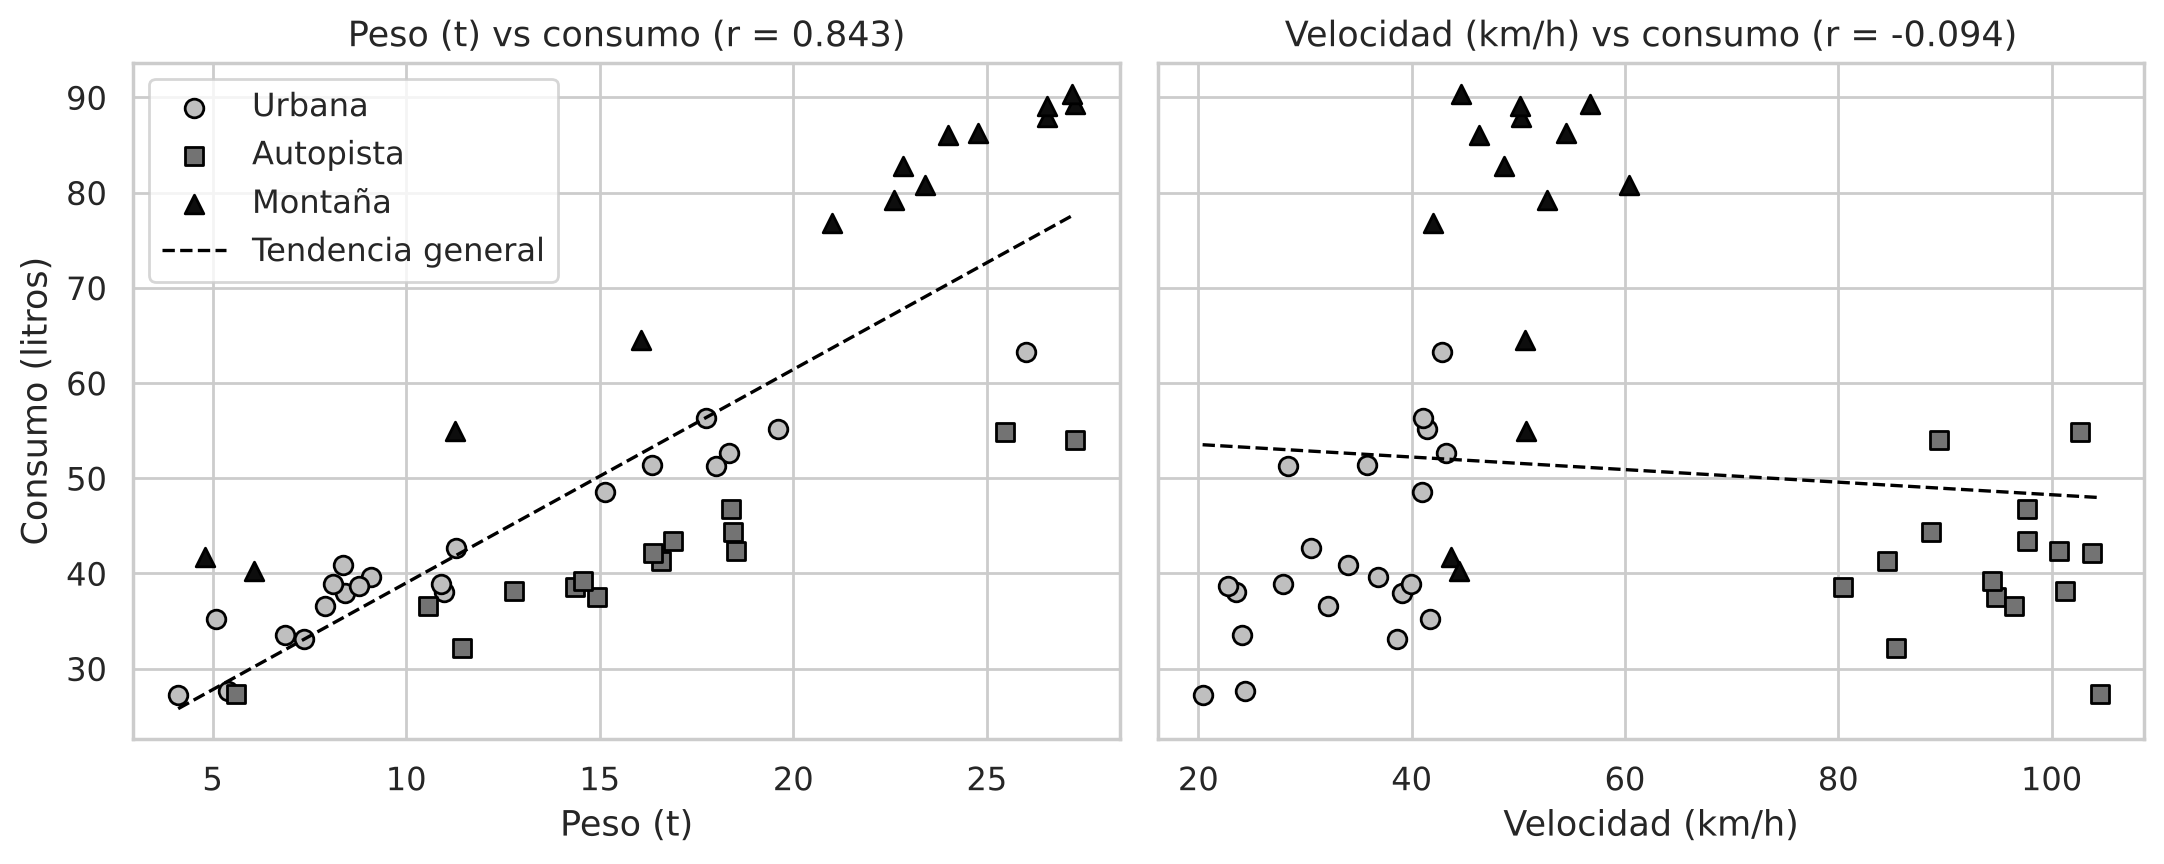

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for r in routes:
    sub = data[data["Tipo_Ruta"] == r]
    axes[0].scatter(sub["Peso_Carga_Ton"], sub["Consumo_Litros"], marker=markers[r], color=grays[r], edgecolor="black", s=45, label=r)
    axes[1].scatter(sub["Velocidad_Promedio_kmh"], sub["Consumo_Litros"], marker=markers[r], color=grays[r], edgecolor="black", s=45, label=r)
for ax, col in zip(axes, ["Peso_Carga_Ton", "Velocidad_Promedio_kmh"]):
    slope, intercept = np.polyfit(data[col], data["Consumo_Litros"], 1)
    xs = np.linspace(data[col].min(), data[col].max(), 50)
    ax.plot(xs, intercept + slope * xs, color="black", linestyle="--", linewidth=1.2, label="Tendencia general")
    r = corr_matrix.loc[col, "Consumo_Litros"]
    ax.set_title(f"{labels[col]} vs consumo (r = {r:.3f})")
    ax.set_xlabel(labels[col])
axes[0].set_ylabel("Consumo (litros)")
axes[0].legend()
fig.tight_layout()
fig.savefig("reporte/figuras/fig3_dispersion.pdf")
fig.savefig("reporte/figuras/fig3_dispersion.png", dpi=150)
plt.show()

**Lectura:** el peso tiene una correlación positiva fuerte con el consumo (r = 0.84). La velocidad casi no se relaciona con el consumo en el conjunto (r = −0.09, no significativa), pero la gráfica muestra que la velocidad depende de la ruta: los camiones de autopista van a 80–105 km/h, los de ciudad a 20–43 km/h y los de montaña a 42–60 km/h. Por eso la velocidad sola es engañosa y hay que leerla junto con la ruta.

## 3. Regresión lineal múltiple
### 3.1 Modelo 1 (el que pide el caso): Consumo = b0 + b1·Peso + b2·Velocidad

In [10]:
model_1 = smf.ols("Consumo_Litros ~ Peso_Carga_Ton + Velocidad_Promedio_kmh", data=data).fit()
coef_1 = pd.DataFrame({"coef": model_1.params, "error est.": model_1.bse, "t": model_1.tvalues,
                       "valor p": model_1.pvalues, "IC 2.5%": model_1.conf_int()[0], "IC 97.5%": model_1.conf_int()[1]})
print("Coeficientes del Modelo 1:")
print(coef_1.to_string(float_format=lambda v: f"{v:.4f}", formatters={"valor p": lambda v: f"{v:.3e}"}))
b = model_1.params
print(f"\nEcuación: Consumo = {b['Intercept']:.4f} + {b['Peso_Carga_Ton']:.4f}·Peso {b['Velocidad_Promedio_kmh']:+.4f}·Velocidad")
print(f"R² = {model_1.rsquared:.4f}   R² ajustado = {model_1.rsquared_adj:.4f}")
print(f"F = {model_1.fvalue:.4f}, p = {model_1.f_pvalue:.3e}")
for name, p in model_1.pvalues.items():
    print(f"  {name:25s} p = {p:.3e} -> {'significativo' if p < alpha else 'NO significativo'}")

Coeficientes del Modelo 1:
                          coef  error est.       t   valor p  IC 2.5%  IC 97.5%
Intercept              26.1794      3.4618  7.5624 1.154e-09  19.2152   33.1436
Peso_Carga_Ton          2.4600      0.1748 14.0706 1.809e-18   2.1082    2.8117
Velocidad_Promedio_kmh -0.2290      0.0462 -4.9589 9.666e-06  -0.3219   -0.1361

Ecuación: Consumo = 26.1794 + 2.4600·Peso -0.2290·Velocidad
R² = 0.8098   R² ajustado = 0.8017
F = 100.0802, p = 1.146e-17
  Intercept                 p = 1.154e-09 -> significativo
  Peso_Carga_Ton            p = 1.809e-18 -> significativo
  Velocidad_Promedio_kmh    p = 9.666e-06 -> significativo


### 3.2 Modelo 2: se agrega el tipo de ruta (variables ficticias, Autopista como referencia)

In [11]:
model_2 = smf.ols("Consumo_Litros ~ Peso_Carga_Ton + Velocidad_Promedio_kmh + C(Tipo_Ruta, Treatment('Autopista'))", data=data).fit()
coef_2 = pd.DataFrame({"coef": model_2.params, "error est.": model_2.bse, "t": model_2.tvalues,
                       "valor p": model_2.pvalues, "IC 2.5%": model_2.conf_int()[0], "IC 97.5%": model_2.conf_int()[1]})
coef_2.index = ["Intercepto", "Ruta Urbana", "Ruta Montaña", "Peso", "Velocidad"]
print("Coeficientes del Modelo 2:")
print(coef_2.to_string(float_format=lambda v: f"{v:.4f}", formatters={"valor p": lambda v: f"{v:.3e}"}))
c = coef_2["coef"]
print(f"\nEcuación: Consumo = {c['Intercepto']:.4f} + {c['Peso']:.4f}·Peso + {c['Velocidad']:.4f}·Velocidad"
      f" + {c['Ruta Urbana']:.4f}·Urbana + {c['Ruta Montaña']:.4f}·Montaña")
print(f"R² = {model_2.rsquared:.4f}   R² ajustado = {model_2.rsquared_adj:.4f}")
print(f"F = {model_2.fvalue:.4f}, p = {model_2.f_pvalue:.3e}")
for name, p in coef_2["valor p"].items():
    print(f"  {name:15s} p = {p:.3e} -> {'significativo' if p < alpha else 'NO significativo'}")

Coeficientes del Modelo 2:
                coef  error est.       t   valor p  IC 2.5%  IC 97.5%
Intercepto    1.0277      6.2832  0.1636 8.708e-01 -11.6275   13.6828
Ruta Urbana  16.4832      4.2188  3.9071 3.110e-04   7.9862   24.9803
Ruta Montaña 31.8149      3.3995  9.3588 3.975e-12  24.9680   38.6617
Peso          1.7792      0.0765 23.2657 1.010e-26   1.6252    1.9332
Velocidad     0.1212      0.0683  1.7743 8.278e-02  -0.0164    0.2588

Ecuación: Consumo = 1.0277 + 1.7792·Peso + 0.1212·Velocidad + 16.4832·Urbana + 31.8149·Montaña
R² = 0.9748   R² ajustado = 0.9726
F = 435.5240, p = 2.423e-35
  Intercepto      p = 8.708e-01 -> NO significativo
  Ruta Urbana     p = 3.110e-04 -> significativo
  Ruta Montaña    p = 3.975e-12 -> significativo
  Peso            p = 1.010e-26 -> significativo
  Velocidad       p = 8.278e-02 -> NO significativo


### 3.3 Modelo 3: el efecto del peso cambia según la ruta (interacción Peso × Ruta)
Sirve para contestar si conviene evitar alguna ruta con cargas pesadas.

In [12]:
model_3 = smf.ols("Consumo_Litros ~ Velocidad_Promedio_kmh + Peso_Carga_Ton * C(Tipo_Ruta, Treatment('Autopista'))", data=data).fit()
coef_3 = pd.DataFrame({"coef": model_3.params, "valor p": model_3.pvalues})
coef_3.index = ["Intercepto", "Ruta Urbana", "Ruta Montaña", "Velocidad", "Peso", "Peso x Urbana", "Peso x Montaña"]
print("Coeficientes del Modelo 3:")
print(coef_3.to_string(float_format=lambda v: f"{v:.4f}", formatters={"valor p": lambda v: f"{v:.3e}"}))
print(f"R² = {model_3.rsquared:.4f}   R² ajustado = {model_3.rsquared_adj:.4f}")

slope_route = {"Autopista": coef_3.loc["Peso", "coef"],
               "Urbana": coef_3.loc["Peso", "coef"] + coef_3.loc["Peso x Urbana", "coef"],
               "Montaña": coef_3.loc["Peso", "coef"] + coef_3.loc["Peso x Montaña", "coef"]}
print("\nLitros extra por cada tonelada adicional, según la ruta:")
for r in routes:
    print(f"  {r:10s} {slope_route[r]:.3f} L/t")
print(f"\nEn montaña cada tonelada cuesta {slope_route['Montaña'] / slope_route['Autopista']:.2f} veces lo que cuesta en autopista.")

Coeficientes del Modelo 3:
                  coef   valor p
Intercepto      9.5017 4.004e-02
Ruta Urbana    10.9486 3.821e-03
Ruta Montaña   14.5358 3.897e-05
Velocidad       0.1123 1.307e-02
Peso            1.3068 2.628e-17
Peso x Urbana   0.2452 5.655e-02
Peso x Montaña  0.9276 9.136e-10
R² = 0.9910   R² ajustado = 0.9897

Litros extra por cada tonelada adicional, según la ruta:
  Urbana     1.552 L/t
  Autopista  1.307 L/t
  Montaña    2.234 L/t

En montaña cada tonelada cuesta 1.71 veces lo que cuesta en autopista.


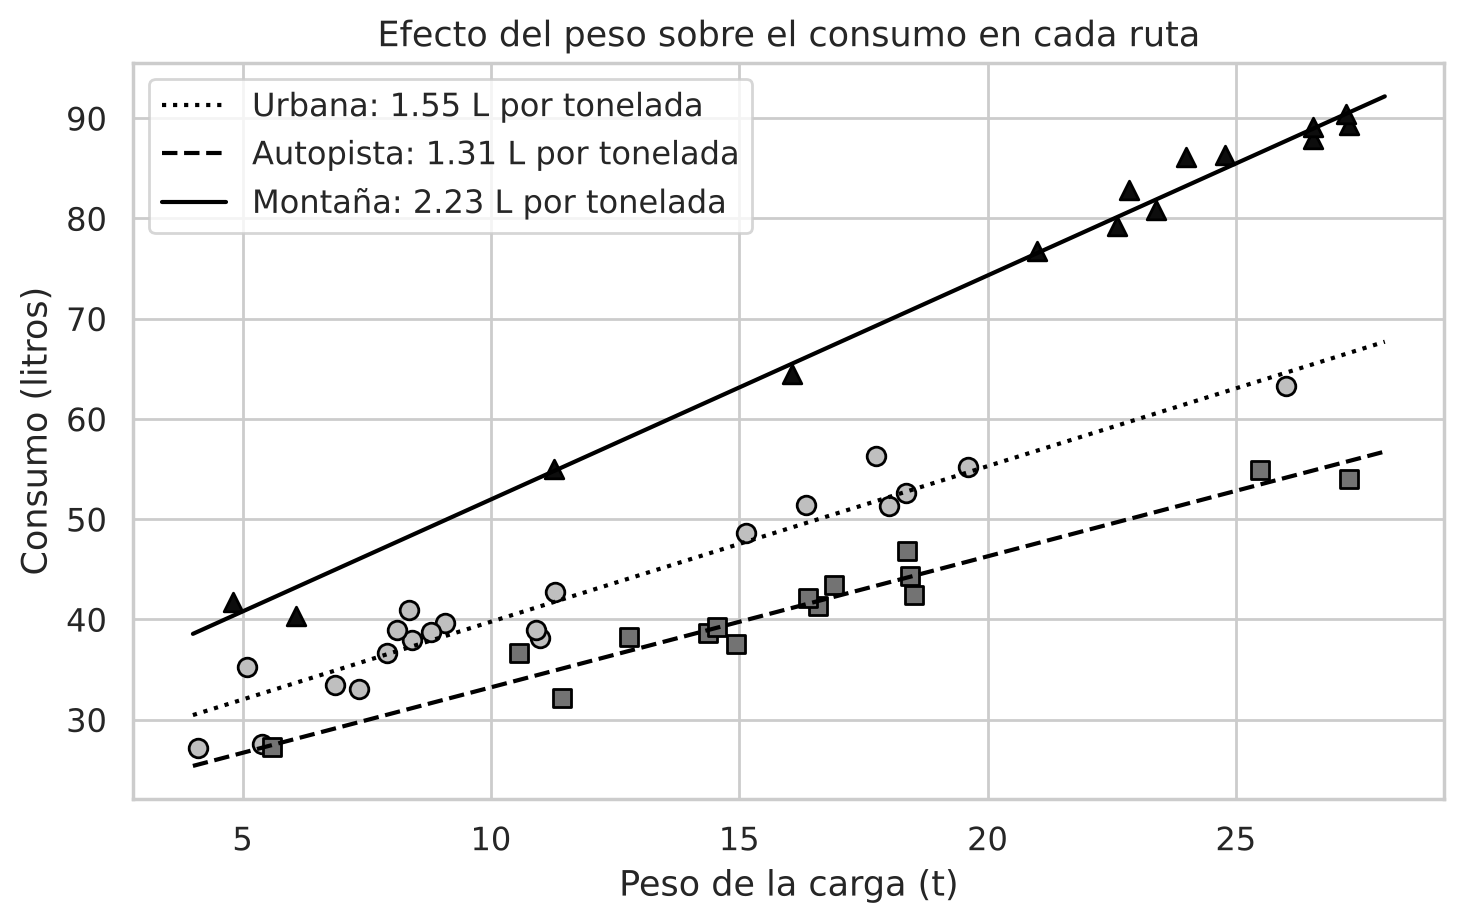

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
linestyles = {"Urbana": ":", "Autopista": "--", "Montaña": "-"}
for r in routes:
    sub = data[data["Tipo_Ruta"] == r]
    ax.scatter(sub["Peso_Carga_Ton"], sub["Consumo_Litros"], marker=markers[r], color=grays[r], edgecolor="black", s=45)
    xs = np.linspace(4, 28, 50)
    line = pd.DataFrame({"Peso_Carga_Ton": xs, "Tipo_Ruta": r, "Velocidad_Promedio_kmh": sub["Velocidad_Promedio_kmh"].mean()})
    ax.plot(xs, model_3.predict(line), color="black", linestyle=linestyles[r], linewidth=1.5,
            label=f"{r}: {slope_route[r]:.2f} L por tonelada")
ax.set_xlabel("Peso de la carga (t)")
ax.set_ylabel("Consumo (litros)")
ax.set_title("Efecto del peso sobre el consumo en cada ruta")
ax.legend()
fig.tight_layout()
fig.savefig("reporte/figuras/fig4_peso_por_ruta.pdf")
fig.savefig("reporte/figuras/fig4_peso_por_ruta.png", dpi=150)
plt.show()

### 3.4 Métricas de rendimiento y comparación de modelos
Además del ajuste con todos los datos, se hace validación cruzada de 5 bloques (cada viaje se predice con un modelo que no lo vio).

In [14]:
y = data["Consumo_Litros"]
dummies = pd.get_dummies(data["Tipo_Ruta"], dtype=float)[["Urbana", "Montaña"]]
X_1 = data[["Peso_Carga_Ton", "Velocidad_Promedio_kmh"]]
X_2 = pd.concat([X_1, dummies], axis=1)
X_3 = X_2.copy()
X_3["Peso_x_Urbana"] = X_3["Peso_Carga_Ton"] * X_3["Urbana"]
X_3["Peso_x_Montaña"] = X_3["Peso_Carga_Ton"] * X_3["Montaña"]
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model, X in [("Modelo 1: Peso + Velocidad", model_1, X_1),
                       ("Modelo 2: + Ruta", model_2, X_2),
                       ("Modelo 3: + Peso x Ruta", model_3, X_3)]:
    y_cv = cross_val_predict(LinearRegression(), X, y, cv=kfold)
    rows.append({"Modelo": name, "R²": model.rsquared, "R² ajustado": model.rsquared_adj,
                 "RMSE (L)": np.sqrt(mean_squared_error(y, model.fittedvalues)),
                 "MAE (L)": mean_absolute_error(y, model.fittedvalues),
                 "R² VC": r2_score(y, y_cv), "RMSE VC (L)": np.sqrt(mean_squared_error(y, y_cv)),
                 "AIC": model.aic})
metrics = pd.DataFrame(rows).set_index("Modelo")
print(metrics.round(4))

print("\nNormalidad de los residuos (Shapiro-Wilk):")
for name, model in [("Modelo 1", model_1), ("Modelo 2", model_2), ("Modelo 3", model_3)]:
    print(f"  {name}: p = {stats.shapiro(model.resid).pvalue:.4f}")

print("\nVIF (multicolinealidad):")
X_vif = X_2.copy()
X_vif.insert(0, "const", 1.0)
for i, col in enumerate(X_vif.columns[1:], start=1):
    print(f"  {col:25s} VIF = {variance_inflation_factor(X_vif.values, i):.2f}")

                                R²  R² ajustado  RMSE (L)  MAE (L)   R² VC  \
Modelo                                                                       
Modelo 1: Peso + Velocidad  0.8098       0.8017    8.2067   6.9947  0.7809   
Modelo 2: + Ruta            0.9748       0.9726    2.9863   2.3906  0.9657   
Modelo 3: + Peso x Ruta     0.9910       0.9897    1.7878   1.4686  0.9870   

                            RMSE VC (L)       AIC  
Modelo                                             
Modelo 1: Peso + Velocidad       8.8100  358.3887  
Modelo 2: + Ruta                 3.4873  261.2989  
Modelo 3: + Peso x Ruta          2.1462  213.9922  

Normalidad de los residuos (Shapiro-Wilk):
  Modelo 1: p = 0.0333
  Modelo 2: p = 0.2048
  Modelo 3: p = 0.6834

VIF (multicolinealidad):
  Peso_Carga_Ton            VIF = 1.48
  Velocidad_Promedio_kmh    VIF = 16.88
  Urbana                    VIF = 21.88
  Montaña                   VIF = 11.76


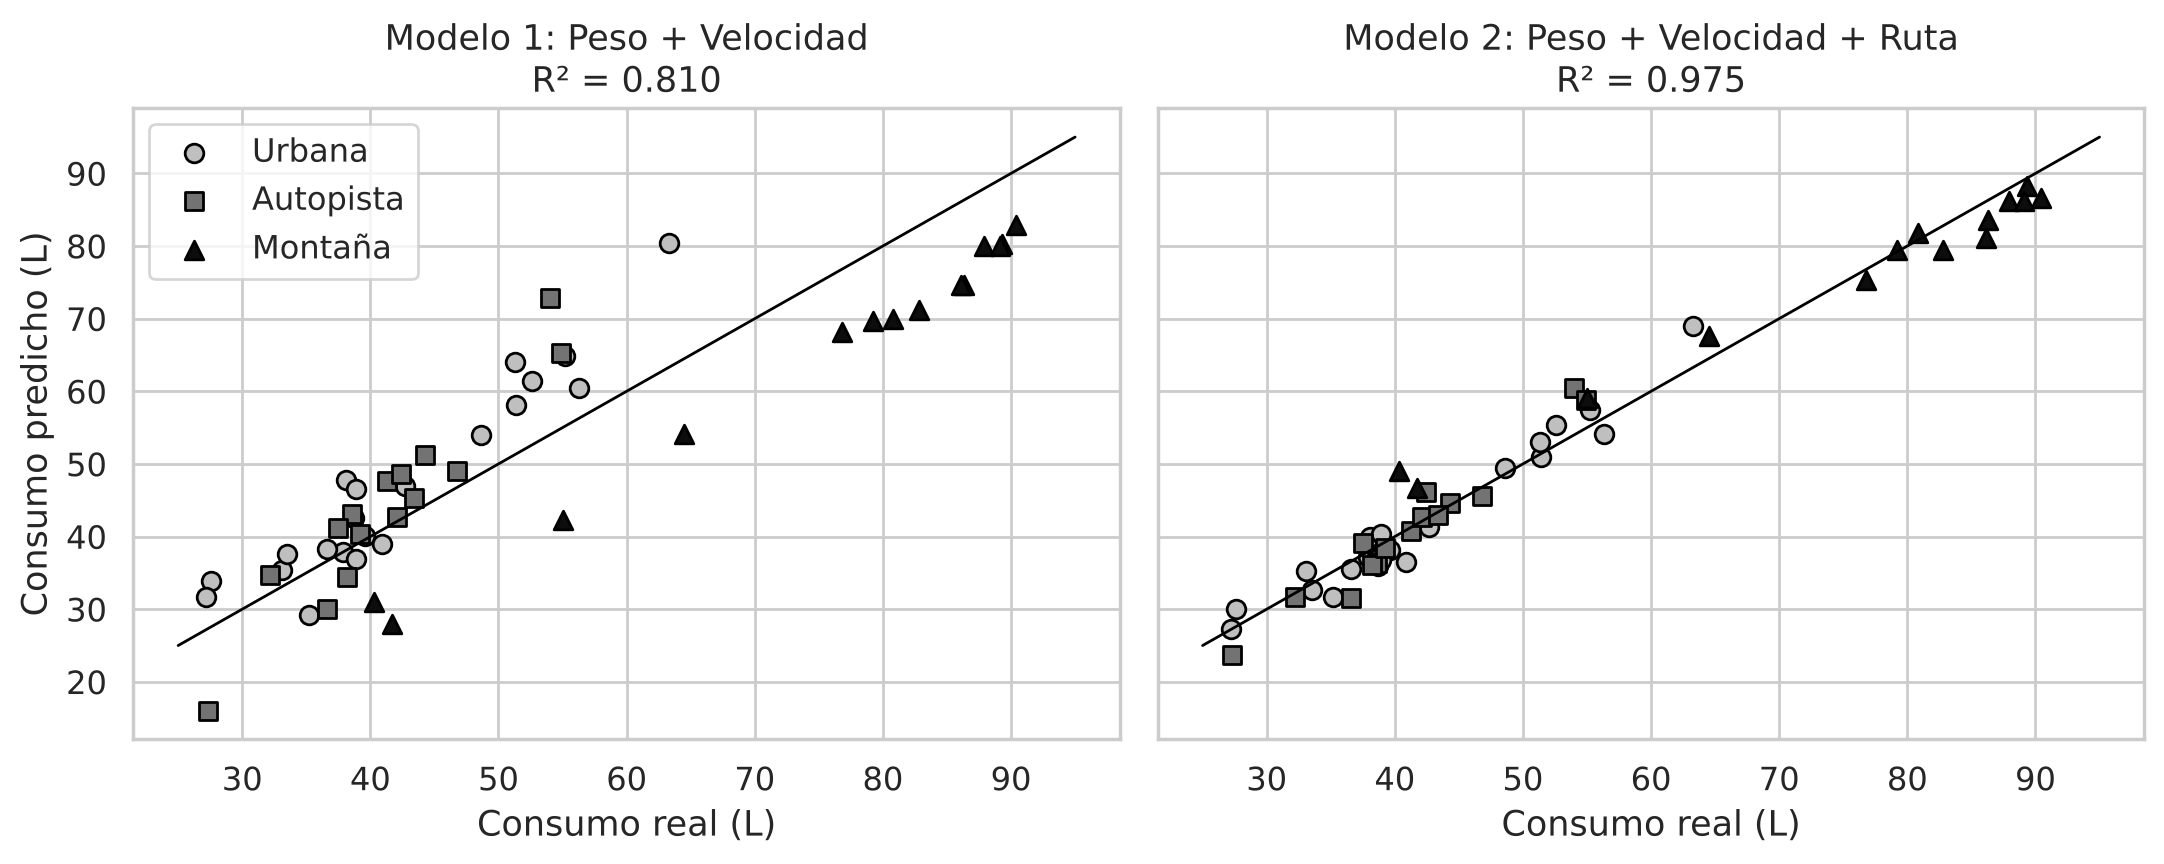

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, model, title in [(axes[0], model_1, "Modelo 1: Peso + Velocidad"), (axes[1], model_2, "Modelo 2: Peso + Velocidad + Ruta")]:
    for r in routes:
        mask = data["Tipo_Ruta"] == r
        ax.scatter(y[mask], model.fittedvalues[mask], marker=markers[r], color=grays[r], edgecolor="black", s=45, label=r)
    ax.plot([25, 95], [25, 95], color="black", linewidth=1)
    ax.set_title(f"{title}\nR² = {model.rsquared:.3f}")
    ax.set_xlabel("Consumo real (L)")
axes[0].set_ylabel("Consumo predicho (L)")
axes[0].legend()
fig.tight_layout()
fig.savefig("reporte/figuras/fig5_real_vs_predicho.pdf")
fig.savefig("reporte/figuras/fig5_real_vs_predicho.png", dpi=150)
plt.show()

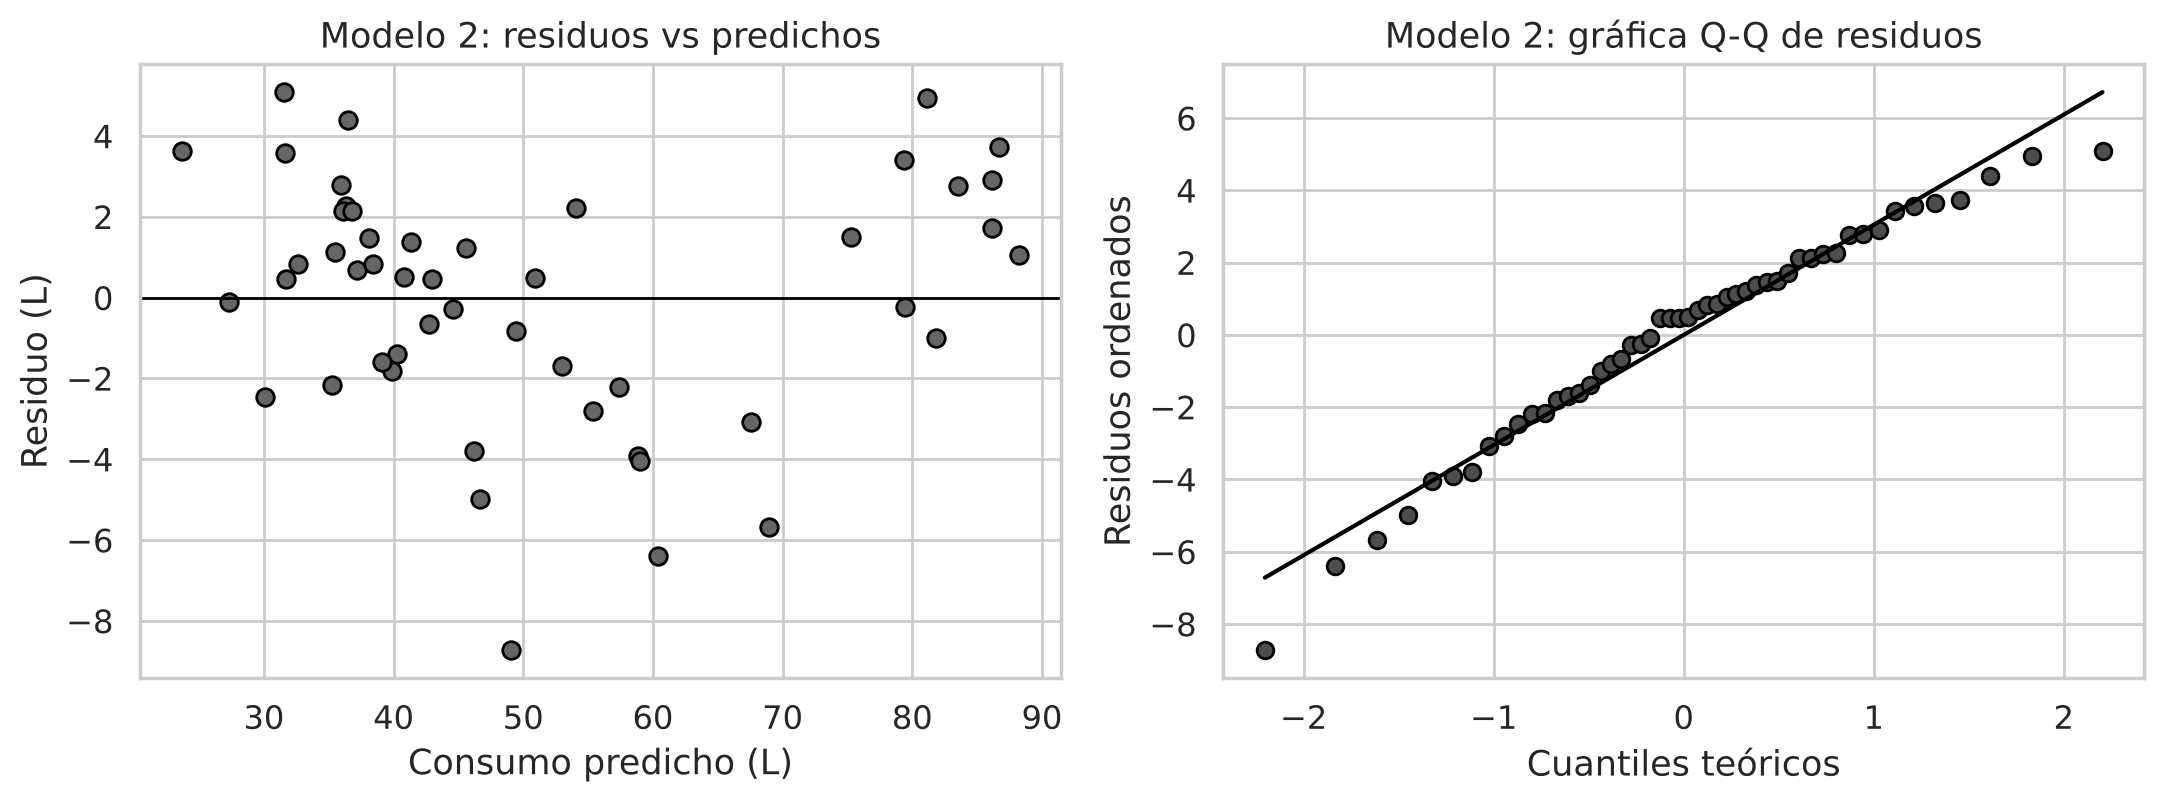

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(model_2.fittedvalues, model_2.resid, color="0.4", edgecolor="black", s=40)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xlabel("Consumo predicho (L)")
axes[0].set_ylabel("Residuo (L)")
axes[0].set_title("Modelo 2: residuos vs predichos")
stats.probplot(model_2.resid, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(color="0.3", markeredgecolor="black")
axes[1].get_lines()[1].set(color="black")
axes[1].set_title("Modelo 2: gráfica Q-Q de residuos")
axes[1].set_xlabel("Cuantiles teóricos")
axes[1].set_ylabel("Residuos ordenados")
fig.tight_layout()
fig.savefig("reporte/figuras/fig6_residuos.pdf")
fig.savefig("reporte/figuras/fig6_residuos.png", dpi=150)
plt.show()

### 3.5 ¿Pesa más la velocidad o el peso? (coeficientes estandarizados)
Los coeficientes normales tienen unidades distintas (L/t y L por km/h), así que para compararlos se estandarizan: cuántas desviaciones estándar cambia el consumo cuando la variable sube una desviación estándar.

In [17]:
std = data[numeric_cols].std()
rows = []
for name, model, w_name, v_name in [("Modelo 1", model_1, "Peso_Carga_Ton", "Velocidad_Promedio_kmh"),
                                    ("Modelo 2", model_2, "Peso_Carga_Ton", "Velocidad_Promedio_kmh")]:
    bw = model.params[w_name]
    bv = model.params[v_name]
    rows.append({"Modelo": name, "b Peso (L/t)": bw, "b Velocidad (L por km/h)": bv,
                 "Beta Peso": bw * std[w_name] / std["Consumo_Litros"],
                 "Beta Velocidad": bv * std[v_name] / std["Consumo_Litros"],
                 "p Velocidad": model.pvalues[v_name]})
std_coefs = pd.DataFrame(rows).set_index("Modelo")
print(std_coefs.round(4))

b_w2 = model_2.params["Peso_Carga_Ton"]
b_v2 = model_2.params["Velocidad_Promedio_kmh"]
print(f"\nCon el Modelo 2: bajar 5 t ahorra {5 * b_w2:.2f} L por viaje; bajar 10 km/h ahorra {10 * b_v2:.2f} L (y no es significativo).")

          b Peso (L/t)  b Velocidad (L por km/h)  Beta Peso  Beta Velocidad  \
Modelo                                                                        
Modelo 1        2.4600                   -0.2290     0.9246         -0.3258   
Modelo 2        1.7792                    0.1212     0.6687          0.1725   

          p Velocidad  
Modelo                 
Modelo 1       0.0000  
Modelo 2       0.0828  

Con el Modelo 2: bajar 5 t ahorra 8.90 L por viaje; bajar 10 km/h ahorra 1.21 L (y no es significativo).


## 4. Pronóstico: camión con 15 toneladas a 80 km/h

In [18]:
new_truck = pd.DataFrame({"Peso_Carga_Ton": [15], "Velocidad_Promedio_kmh": [80]})
pred_1 = model_1.get_prediction(new_truck).summary_frame(alpha=alpha)
y_hat_1 = pred_1["mean"].iloc[0]
print("Modelo 1 (Peso + Velocidad):")
print(f"  Consumo = {b['Intercept']:.4f} + {b['Peso_Carga_Ton']:.4f}(15) {b['Velocidad_Promedio_kmh']:+.4f}(80) = {y_hat_1:.2f} L")
print(f"  IC 95% de la media: [{pred_1['mean_ci_lower'].iloc[0]:.2f}, {pred_1['mean_ci_upper'].iloc[0]:.2f}] L")
print(f"  Intervalo de predicción 95% (un viaje): [{pred_1['obs_ci_lower'].iloc[0]:.2f}, {pred_1['obs_ci_upper'].iloc[0]:.2f}] L")

new_trucks = pd.DataFrame({"Peso_Carga_Ton": [15] * 3, "Velocidad_Promedio_kmh": [80] * 3, "Tipo_Ruta": routes})
pred_2 = model_2.get_prediction(new_trucks).summary_frame(alpha=alpha)
pred_2.index = routes
print("\nModelo 2 (con ruta):")
speed_range = data.groupby("Tipo_Ruta", observed=True)["Velocidad_Promedio_kmh"].agg(["min", "max"])
for r in routes:
    low, high = speed_range.loc[r, "min"], speed_range.loc[r, "max"]
    if low - 1 <= 80 <= high + 1:
        note = f"  (80 km/h está dentro o en el borde del rango observado, {low}-{high} km/h)"
    else:
        note = f"  (extrapolación: en {r} la velocidad observada va de {low} a {high} km/h)"
    print(f"  {r:10s} {pred_2.loc[r, 'mean']:.2f} L   IP 95% [{pred_2.loc[r, 'obs_ci_lower']:.2f}, {pred_2.loc[r, 'obs_ci_upper']:.2f}]{note}")

Modelo 1 (Peso + Velocidad):
  Consumo = 26.1794 + 2.4600(15) -0.2290(80) = 44.76 L
  IC 95% de la media: [41.48, 48.03] L
  Intervalo de predicción 95% (un viaje): [27.42, 62.10] L

Modelo 2 (con ruta):
  Urbana     53.90 L   IP 95% [44.90, 62.89]  (extrapolación: en Urbana la velocidad observada va de 20.4 a 43.2 km/h)
  Autopista  37.41 L   IP 95% [30.57, 44.26]  (80 km/h está dentro o en el borde del rango observado, 80.4-104.5 km/h)
  Montaña    69.23 L   IP 95% [61.28, 77.17]  (extrapolación: en Montaña la velocidad observada va de 42.0 a 60.4 km/h)


## 5. Toma de decisiones (resumen)

In [19]:
print("1) ¿Evitar ciertas rutas para cargas pesadas?")
print(f"   Sí, la montaña. Cada tonelada extra cuesta {slope_route['Montaña']:.2f} L en montaña, "
      f"{slope_route['Urbana']:.2f} L en ciudad y {slope_route['Autopista']:.2f} L en autopista. "
      "Las cargas pesadas conviene mandarlas por autopista o dividirlas.")
print("\n2) ¿En qué ruta se gasta más y es significativo?")
print(f"   Montaña: {desc_route.loc['Montaña', 'mean']:.2f} L promedio vs {desc_route.loc['Urbana', 'mean']:.2f} (Urbana) "
      f"y {desc_route.loc['Autopista', 'mean']:.2f} (Autopista). ANOVA F = {f_stat:.2f}, p = {p_value:.2e}: sí es significativo. "
      "Tukey: Montaña difiere de las otras dos; Urbana y Autopista no difieren.")
print("\n3) ¿Controlar la velocidad o el peso?")
print(f"   El peso. Es significativo en todos los modelos y su efecto estandarizado es casi 4 veces el de la velocidad "
      f"(beta = {std_coefs.loc['Modelo 2', 'Beta Peso']:.2f} vs {std_coefs.loc['Modelo 2', 'Beta Velocidad']:.2f} en el Modelo 2). "
      f"Bajar 5 t ahorra {5 * b_w2:.1f} L por viaje; bajar 10 km/h solo {10 * b_v2:.1f} L. "
      "La velocidad sale negativa en el Modelo 1 solo porque los camiones rápidos van por autopista; "
      f"al controlar la ruta su efecto es pequeño (p = {model_2.pvalues['Velocidad_Promedio_kmh']:.3f} en el Modelo 2).")
print("\n4) Pronóstico para 15 t a 80 km/h:")
print(f"   Modelo 1: {y_hat_1:.2f} L.  Modelo 2 (en autopista, que es donde se circula a 80 km/h): {pred_2.loc['Autopista', 'mean']:.2f} L.")

1) ¿Evitar ciertas rutas para cargas pesadas?
   Sí, la montaña. Cada tonelada extra cuesta 2.23 L en montaña, 1.55 L en ciudad y 1.31 L en autopista. Las cargas pesadas conviene mandarlas por autopista o dividirlas.

2) ¿En qué ruta se gasta más y es significativo?
   Montaña: 75.01 L promedio vs 42.27 (Urbana) y 41.25 (Autopista). ANOVA F = 39.47, p = 8.73e-11: sí es significativo. Tukey: Montaña difiere de las otras dos; Urbana y Autopista no difieren.

3) ¿Controlar la velocidad o el peso?
   El peso. Es significativo en todos los modelos y su efecto estandarizado es casi 4 veces el de la velocidad (beta = 0.67 vs 0.17 en el Modelo 2). Bajar 5 t ahorra 8.9 L por viaje; bajar 10 km/h solo 1.2 L. La velocidad sale negativa en el Modelo 1 solo porque los camiones rápidos van por autopista; al controlar la ruta su efecto es pequeño (p = 0.083 en el Modelo 2).

4) Pronóstico para 15 t a 80 km/h:
   Modelo 1: 44.76 L.  Modelo 2 (en autopista, que es donde se circula a 80 km/h): 37.41 L.
